# Класифікатор «є корабель / немає»

Етап 5. Тут — локальна перевірка (CPU, `data/train_micro/`), що дані подаються в мережу правильно.
Модель і навчання — у `03_classifier_train.ipynb`.

## 1. Перевірка `Dataset` (`src/dataset.py`)

Що перевіряємо:
1. `Dataset` повертає тензор форми `[3, 384, 384]` і мітку 0.0 / 1.0.
2. Нормалізація зворотна: якщо «рознормалізувати» тензор, отримаємо початковий знімок.
3. **Очима:** аугментації (відбиття, повороти на 90°) однаково змінюють знімок і маску —
   корабель лишається під своєю маскою.
4. `DataLoader` склеює приклади в батч `[B, 3, 384, 384]`.
5. `balanced_sample` дає порівну знімків з кораблями і без.

In [7]:
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch.utils.data import DataLoader

ROOT = Path.cwd().parent
sys.path.append(str(ROOT / "src"))
from dataset import (IMAGE_SIZE, IMAGENET_MEAN, IMAGENET_STD, ShipClassificationDataset,
                     augment, balanced_sample, read_image, to_tensor)
from rle import rle_decode

DATA_DIR = ROOT / "data"
IMAGES_DIR = DATA_DIR / "train_micro"
SEED = 42
torch.manual_seed(SEED)

sample = pd.read_csv(DATA_DIR / "sample_ids.csv")
masks = pd.read_csv(DATA_DIR / "train_ship_segmentations_v2.csv")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


### 1.1. Один приклад

Мінімум і максимум після нормалізації мають бути приблизно в межах −2.1…+2.6:
(0 − 0.485) / 0.229 ≈ −2.1 для чорного пікселя, (1 − 0.406) / 0.225 ≈ 2.6 для білого.

In [8]:
dataset = ShipClassificationDataset(sample["ImageId"], sample["n_ships"] > 0, IMAGES_DIR, train=True)
image, label = dataset[0]

print("знімків у Dataset:", len(dataset))
print("форма:", image.shape, image.dtype)
print(f"min / max: {image.min():.2f} / {image.max():.2f}")
print("мітка:", label)
assert image.shape == (3, IMAGE_SIZE, IMAGE_SIZE)

знімків у Dataset: 300
форма: torch.Size([3, 384, 384]) torch.float32
min / max: -2.12 / -0.24
мітка: tensor(0.)


### 1.2. Нормалізація зворотна

Беремо знімок, робимо `to_tensor`, потім обернену операцію (× std + mean, назад до `[H, W, C]`).
Має вийти той самий знімок з точністю до округлення.

In [9]:
original = read_image(IMAGES_DIR / sample["ImageId"][0])
restored = to_tensor(original).numpy().transpose(1, 2, 0) * IMAGENET_STD + IMAGENET_MEAN
restored = np.round(restored * 255).astype(np.uint8)
print("макс. різниця в пікселях:", np.abs(restored.astype(int) - original.astype(int)).max())

макс. різниця в пікселях: 0


### 1.3. Аугментації очима

Для кількох знімків з кораблями: ліворуч оригінал, далі 3 випадкові аугментації.
Червоним (напівпрозоро) — маска кораблів, повернута **тією самою** аугментацією. Корабель має лишатися під маскою.

Маску зменшуємо до 384 через `INTER_NEAREST`: він бере найближчий піксель і не створює
«проміжних» значень між 0 і 1.

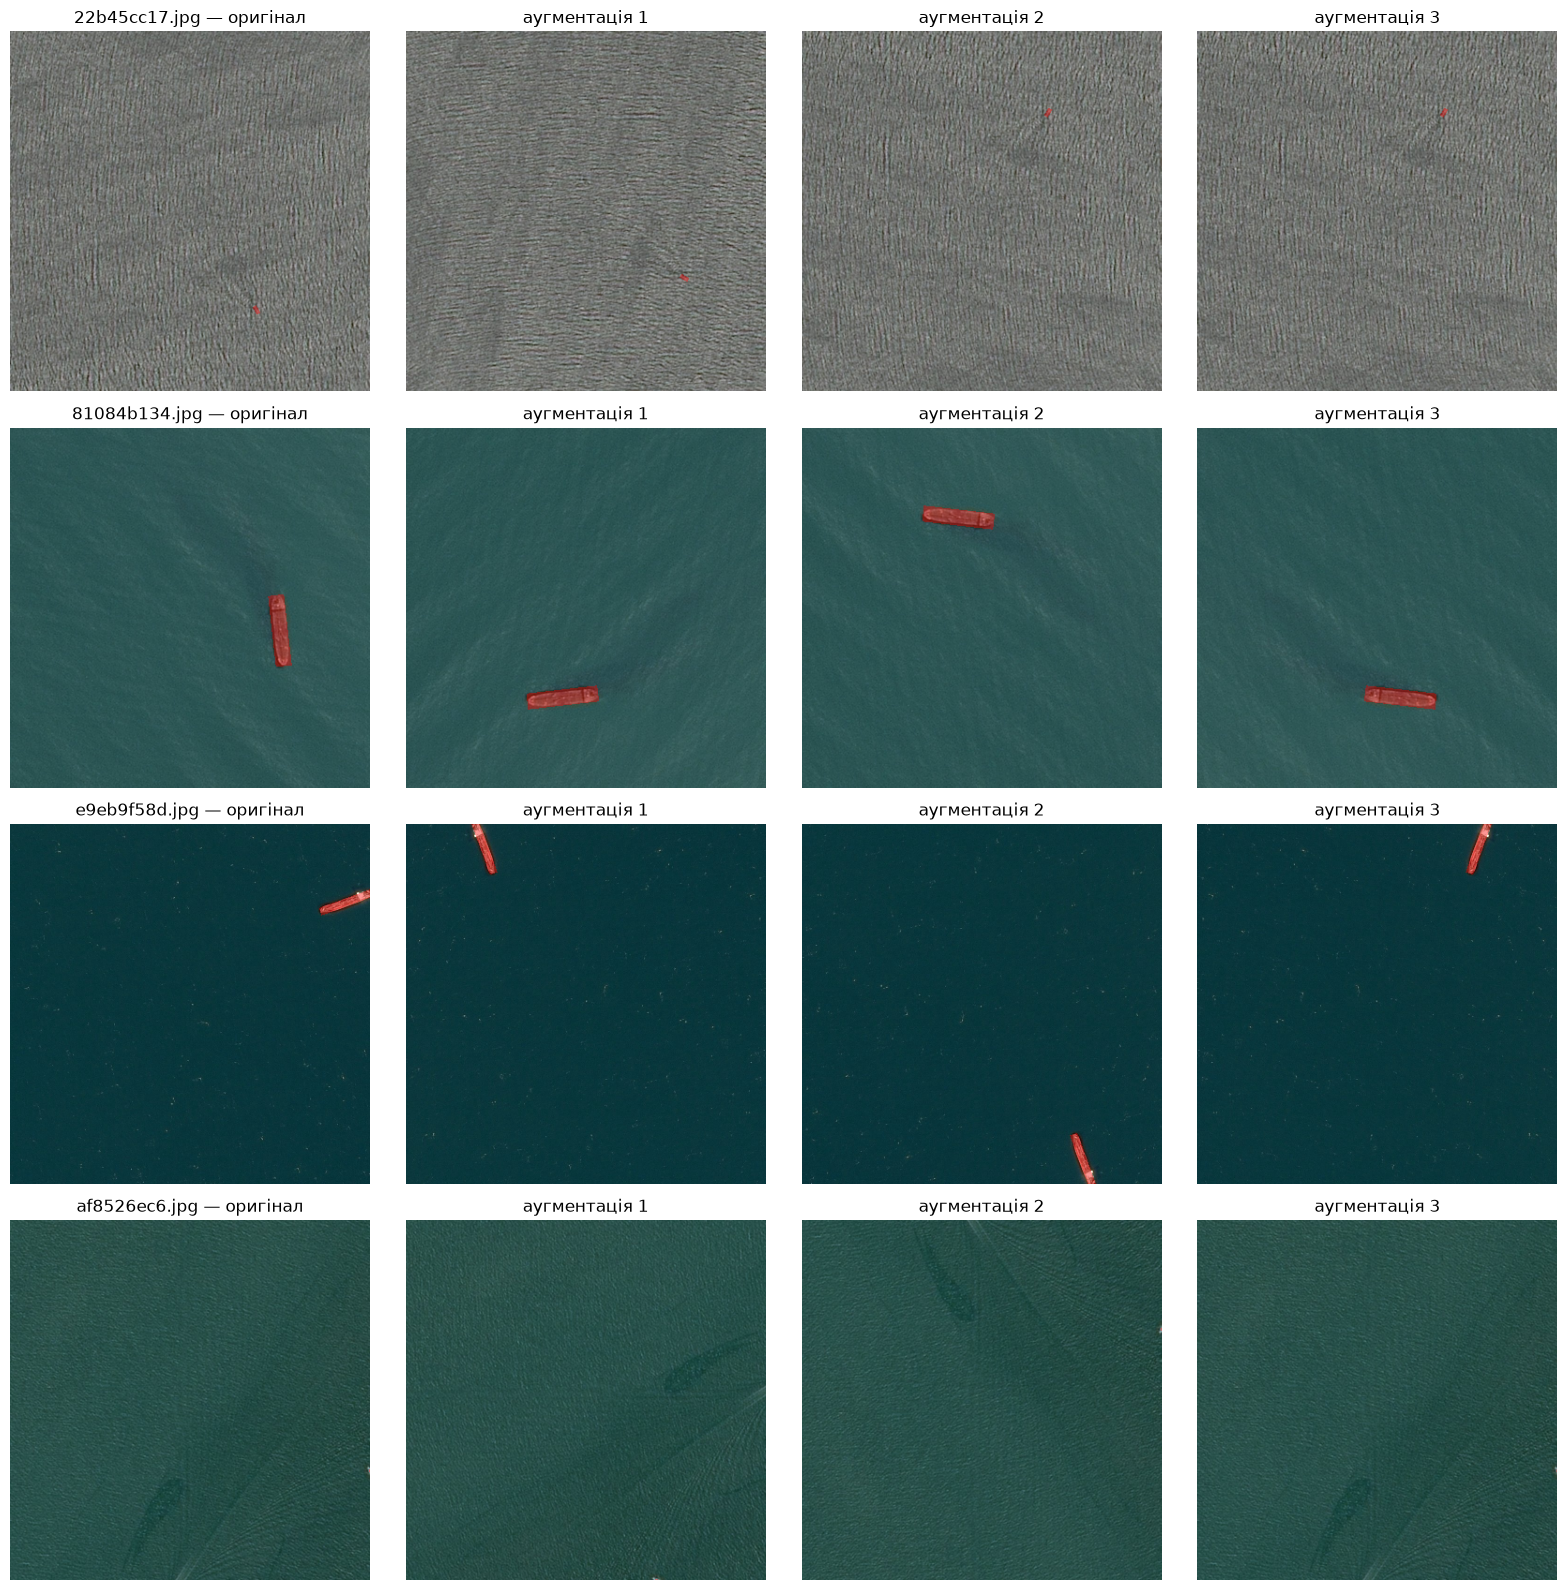

In [10]:
def ships_mask(image_id, size=IMAGE_SIZE):
    rles = masks.loc[masks["ImageId"] == image_id, "EncodedPixels"].dropna()
    mask = np.zeros((768, 768), dtype=np.uint8)
    for rle in rles:
        mask |= rle_decode(rle)
    return cv2.resize(mask, (size, size), interpolation=cv2.INTER_NEAREST)


def show_with_mask(ax, image, mask, title):
    overlay = image.copy()
    overlay[mask == 1] = [255, 0, 0]
    # Напівпрозора маска — щоб під нею було видно сам корабель.
    ax.imshow(cv2.addWeighted(image, 0.6, overlay, 0.4, 0))
    ax.set_title(title)
    ax.axis("off")


ids_with_ships = sample.loc[sample["n_ships"] > 0, "ImageId"].iloc[:4]
fig, axes = plt.subplots(len(ids_with_ships), 4, figsize=(16, 4 * len(ids_with_ships)))
for row, image_id in enumerate(ids_with_ships):
    image = read_image(IMAGES_DIR / image_id)
    mask = ships_mask(image_id)
    show_with_mask(axes[row, 0], image, mask, f"{image_id} — оригінал")
    for col in range(1, 4):
        aug_image, aug_mask = augment(image, mask)
        show_with_mask(axes[row, col], aug_image, aug_mask, f"аугментація {col}")
plt.tight_layout()
plt.show()

**Висновки з картинки:**

- Аугментації працюють: корабель лишається під маскою після відбиттів і поворотів, зокрема біля краю знімка.
- **Знімок `af8526ec6.jpg` (4-й рядок) — корабель, якого майже не видно.** У CSV на ньому один корабель
  площею **21 піксель** (при 768), у стовпцях 765–767 — останні 3 стовпці знімка. Знімки нарізані з більших
  сцен, і в кадр потрапив лише кінчик корабля, решта — на сусідньому знімку. Після зменшення до 384 лишається
  ~5 пікселів (червона цятка біля правого краю). Мітка «є корабель», хоча людина його навряд чи помітить —
  для класифікатора це майже нерозв'язний приклад.
- **Розмітка не ідеальна (label noise, шум у розмітці).** На тому ж знімку посередині видно темний силует,
  схожий на корабель зі слідом, — і маски на ньому немає. Тобто позначено ледь видимий шматок, а помітний
  об'єкт — ні. Модель за такі випадки штрафуватимуть, навіть якщо вона «права», тож **скор 1.0 недосяжний
  навіть для ідеальної моделі**. Це варто пам'ятати, розбираючи помилки моделі.

### 1.4. `DataLoader`

Локально `num_workers=0` — усе в одному процесі, так простіше дебажити.
На Kaggle буде `num_workers=4`.

In [11]:
loader = DataLoader(dataset, batch_size=4, shuffle=True, num_workers=0)
images, labels = next(iter(loader))
print("батч знімків:", images.shape)
print("батч міток:", labels)
assert images.shape == (4, 3, IMAGE_SIZE, IMAGE_SIZE)

батч знімків: torch.Size([4, 3, 384, 384])
батч міток: tensor([1., 0., 1., 1.])


### 1.5. `balanced_sample` на справжньому train

Беремо train-частину з `data/split.csv`: усі знімки з кораблями + стільки ж випадкових порожніх.

In [12]:
split = pd.read_csv(DATA_DIR / "split.csv")
train = split[split["split"] == "train"]
balanced = balanced_sample(train, seed=SEED)

print("train усього:", len(train))
print("після undersampling:", len(balanced))
print((balanced["n_ships"] > 0).value_counts())
assert (balanced["n_ships"] > 0).mean() == 0.5
assert balanced["ImageId"].is_unique

train усього: 173300
після undersampling: 76600
n_ships
True     38300
False    38300
Name: count, dtype: int64
